# Google Street View Landmark Recognition

## 1. Project Overview

This project aims to develop a landmark recognition system using Deep Learning and Computer Vision techniques.

The system processes landmark images, extracts visual features using a pre-trained Convolutional Neural Network (CNN), and classifies images into their corresponding landmark categories using Transfer Learning.

## 2. Project Objectives

- Load and explore a landmark image dataset.
- Preprocess images for deep learning.
- Extract visual features using a pre-trained CNN.
- Build and train a landmark classification model.
- Evaluate model performance using accuracy, precision, recall, and F1-score.
- Visualize landmark predictions and classification results.

## 3. Technologies Used

- Python
- TensorFlow / Keras
- MobileNetV2
- Hugging Face Datasets
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Pillow

## 4. Importing Required Libraries

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

## 5. Loading the Landmark Image Dataset

In [9]:
from datasets import load_dataset

train_url = (
    "https://huggingface.co/datasets/"
    "pemujo/GLDv2_Top_51_Categories/resolve/main/"
    "data/train-00000-of-00005-39f96bd6997c0a5f.parquet"
)

landmark_data = load_dataset(
    "parquet",
    data_files=train_url,
    split="train",
    streaming=True
)

print("Training dataset connected successfully!")

Training dataset connected successfully!


## 6. Inspecting a Sample Dataset Record

In [10]:
sample = next(iter(landmark_data))

print("Available columns:", sample.keys())
print("Landmark ID:", sample["landmark_id"])
print("Category:", sample["category"])
print("Label:", sample["label"])

Available columns: dict_keys(['id', 'landmark_id', 'category', 'image', 'label'])
Landmark ID: 10419
Category: Qutb_Minar_and_its_monuments,_Delhi
Label: 26


## 7. Visualizing a Sample Landmark Image

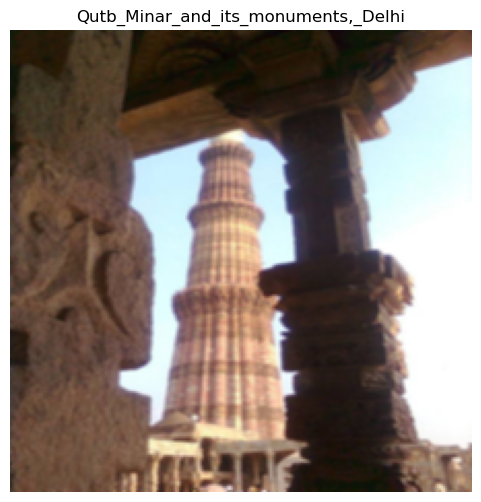

In [11]:
import matplotlib.pyplot as plt

sample_image = sample["image"]

plt.figure(figsize=(6, 6))
plt.imshow(sample_image)
plt.title(sample["category"])
plt.axis("off")
plt.show()

## 8. Exploring Landmark Categories

In [12]:
from collections import Counter

sample_records = []

for record in landmark_data:
    sample_records.append({
        "landmark_id": record["landmark_id"],
        "category": record["category"],
        "label": record["label"]
    })

    if len(sample_records) == 500:
        break

class_counts = Counter(
    record["category"] for record in sample_records
)

print("Images inspected:", len(sample_records))
print("Unique landmark classes:", len(class_counts))
print("\nTop 10 landmark classes:")

for category, count in class_counts.most_common(10):
    print(category, ":", count)

Images inspected: 500
Unique landmark classes: 51

Top 10 landmark classes:
Media_contributed_by_the_ETH-Bibliothek : 72
Corktown,_Toronto : 26
Noraduz_Cemetery : 19
Museum_of_Folk_Architecture_and_Ethnography_in_Pyrohiv : 17
Mathura_Museum : 14
Sofiyivsky_Park : 14
Hayravank_monastery : 13
Qutb_Minar_and_its_monuments,_Delhi : 12
Nieuwe_Waterweg : 12
St._Lawrence,_Toronto : 12


In [13]:
eligible_classes = {
    category: count
    for category, count in class_counts.items()
    if count >= 10
}

print("Classes with at least 10 images:", len(eligible_classes))

print("\nEligible classes:")
for category, count in eligible_classes.items():
    print(category, ":", count)

Classes with at least 10 images: 18

Eligible classes:
Qutb_Minar_and_its_monuments,_Delhi : 12
Media_contributed_by_the_ETH-Bibliothek : 72
Sal%C3%A8ve : 10
Corktown,_Toronto : 26
Golden_Gate_Bridge : 10
Nieuwe_Waterweg : 12
Niagara_Falls : 10
St._Lawrence,_Toronto : 12
Noraduz_Cemetery : 19
Douthat_State_Park : 11
Hayravank_monastery : 13
Mathura_Museum : 14
Catedral_San_Sebasti%C3%A1n,_Cochabamba : 12
Museum_of_Folk_Architecture_and_Ethnography_in_Pyrohiv : 17
Skopje_Fortress : 10
Faisal_Mosque : 12
Haleakal%C4%81_National_Park : 11
Sofiyivsky_Park : 14


## 9. Selecting Landmark Categories

In [14]:
selected_categories = [
    "Qutb_Minar_and_its_monuments,_Delhi",
    "Corktown,_Toronto",
    "Golden_Gate_Bridge",
    "Niagara_Falls",
    "Noraduz_Cemetery",
    "Hayravank_monastery",
    "Mathura_Museum",
    "Skopje_Fortress",
    "Faisal_Mosque",
    "Sofiyivsky_Park"
]

print("Selected landmark classes:", len(selected_categories))

for category in selected_categories:
    print(category)

Selected landmark classes: 10
Qutb_Minar_and_its_monuments,_Delhi
Corktown,_Toronto
Golden_Gate_Bridge
Niagara_Falls
Noraduz_Cemetery
Hayravank_monastery
Mathura_Museum
Skopje_Fortress
Faisal_Mosque
Sofiyivsky_Park


## 10. Collecting Landmark Images

In [15]:
from collections import defaultdict

landmark_images = defaultdict(list)

for record in landmark_data:
    category = record["category"]

    if category in selected_categories:
        if len(landmark_images[category]) < 30:
            landmark_images[category].append(record["image"])

    if all(len(landmark_images[c]) >= 30 for c in selected_categories):
        break

print("Images collected:", sum(len(v) for v in landmark_images.values()))

for category, images in landmark_images.items():
    print(category, ":", len(images))

Images collected: 300
Qutb_Minar_and_its_monuments,_Delhi : 30
Corktown,_Toronto : 30
Golden_Gate_Bridge : 30
Niagara_Falls : 30
Noraduz_Cemetery : 30
Hayravank_monastery : 30
Mathura_Museum : 30
Skopje_Fortress : 30
Faisal_Mosque : 30
Sofiyivsky_Park : 30


## 11. Preprocessing Landmark Images

In [16]:
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

X = []
y = []

for label, category in enumerate(selected_categories):
    for img in landmark_images[category]:
        img = img.convert("RGB").resize((224, 224))
        X.append(np.array(img))
        y.append(label)

X = preprocess_input(np.array(X, dtype=np.float32))
y = np.array(y)

print("Image data shape:", X.shape)
print("Label data shape:", y.shape)

Image data shape: (300, 224, 224, 3)
Label data shape: (300,)


## 12. Splitting the Dataset into Training and Testing Sets

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])

Training images: 240
Testing images: 60


## 13. Loading the Pretrained MobileNetV2 Model

In [18]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Pretrained layers:", len(base_model.layers))

MobileNetV2 loaded successfully!
Pretrained layers: 154


## 14. Building the Landmark Classification Model

In [19]:
from tensorflow.keras import layers, models

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 15. Compiling the Model

In [20]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


## 16. Training the Landmark Classification Model

In [21]:
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=16,
    validation_split=0.2
)

Epoch 1/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 440ms/step - accuracy: 0.2917 - loss: 2.1991 - val_accuracy: 0.6250 - val_loss: 1.3157
Epoch 2/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.7917 - loss: 0.8696 - val_accuracy: 0.8125 - val_loss: 0.8501
Epoch 3/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 247ms/step - accuracy: 0.8802 - loss: 0.4624 - val_accuracy: 0.8125 - val_loss: 0.6455
Epoch 4/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 257ms/step - accuracy: 0.9323 - loss: 0.2777 - val_accuracy: 0.7917 - val_loss: 0.7327
Epoch 5/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 278ms/step - accuracy: 0.9635 - loss: 0.1877 - val_accuracy: 0.7708 - val_loss: 0.6480
Epoch 6/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 264ms/step - accuracy: 0.9740 - loss: 0.1316 - val_accuracy: 0.7917 - val_loss: 0.6232
Epoch 7/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 252ms/step - accuracy: 0.9844 - loss: 0.0930 - val_accuracy: 0.8125 - val_loss: 0.6285
Epoch 8/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 256ms/step - accuracy: 0.9948 - loss: 0.0511 - val_accuracy: 0

## 17. Evaluating Model Performance

In [22]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 413ms/step - accuracy: 0.8500 - loss: 0.4662
Test Loss: 0.4662352204322815
Test Accuracy: 85.00000238418579 %


## 18. Classification Report

In [23]:
from sklearn.metrics import classification_report

y_pred = np.argmax(model.predict(X_test), axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=selected_categories
))

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step
                                     precision    recall  f1-score   support

Qutb_Minar_and_its_monuments,_Delhi       0.67      1.00      0.80         6
                  Corktown,_Toronto       1.00      0.83      0.91         6
                 Golden_Gate_Bridge       0.80      0.67      0.73         6
                      Niagara_Falls       0.71      0.83      0.77         6
                   Noraduz_Cemetery       1.00      0.50      0.67         6
                Hayravank_monastery       0.57      0.67      0.62         6
                     Mathura_Museum       1.00      1.00      1.00         6
                    Skopje_Fortress       1.00      1.00      1.00         6
                      Faisal_Mosque       1.00      1.00      1.00         6
                    Sofiyivsky_Park       1.00      1.00      1.00         6

                           accuracy                           0.85        60
                          macro avg   

## 19. Saving the Trained Model

In [24]:
import os
import json

os.makedirs("models", exist_ok=True)

model.save("models/landmark_recognition.keras")

with open("models/landmark_classes.json", "w") as f:
    json.dump(selected_categories, f)

print("Model and landmark classes saved successfully!")

Model and landmark classes saved successfully!


## 20. Visualizing and Saving a Landmark Prediction

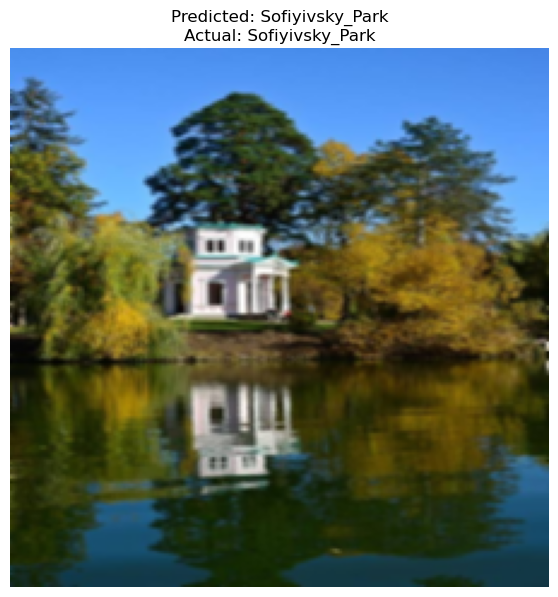

Prediction confidence: 93.1 %
Prediction result saved successfully!


In [25]:
import os
import matplotlib.pyplot as plt
import numpy as np

os.makedirs("results", exist_ok=True)

index = 0

prediction = model.predict(
    np.expand_dims(X_test[index], axis=0),
    verbose=0
)

predicted_label = np.argmax(prediction)
predicted_landmark = selected_categories[predicted_label]
actual_landmark = selected_categories[y_test[index]]

plt.figure(figsize=(7, 7))
plt.imshow((X_test[index] + 1) / 2)
plt.title(
    f"Predicted: {predicted_landmark}\n"
    f"Actual: {actual_landmark}"
)
plt.axis("off")

plt.savefig(
    "results/landmark_prediction.png",
    bbox_inches="tight",
    dpi=150
)

plt.show()

print("Prediction confidence:",
      round(float(np.max(prediction)) * 100, 2), "%")

print("Prediction result saved successfully!")

## 21. Generating and Saving the Confusion Matrix

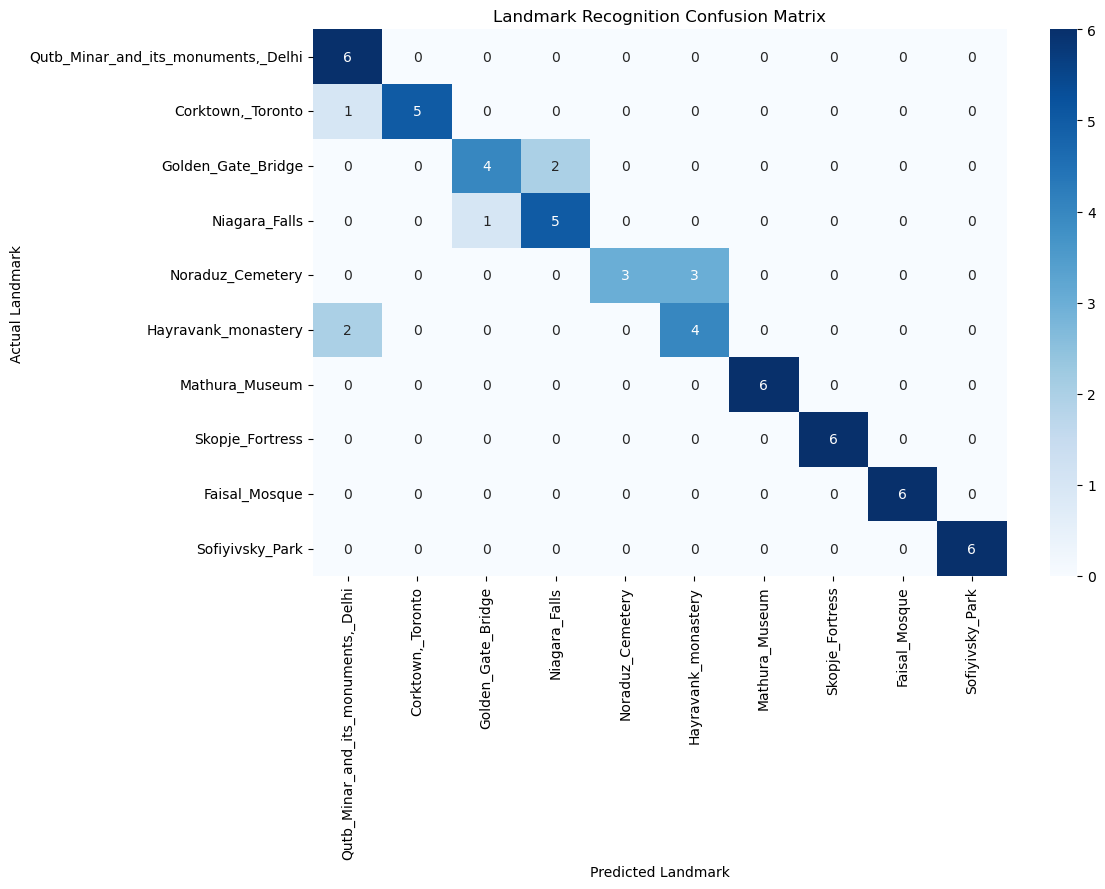

Confusion matrix saved successfully!


In [26]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

os.makedirs("results", exist_ok=True)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=selected_categories,
    yticklabels=selected_categories
)

plt.xlabel("Predicted Landmark")
plt.ylabel("Actual Landmark")
plt.title("Landmark Recognition Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "results/confusion_matrix.png",
    bbox_inches="tight",
    dpi=150
)

plt.show()

print("Confusion matrix saved successfully!")

## 22. Visualizing Training and Validation Performance

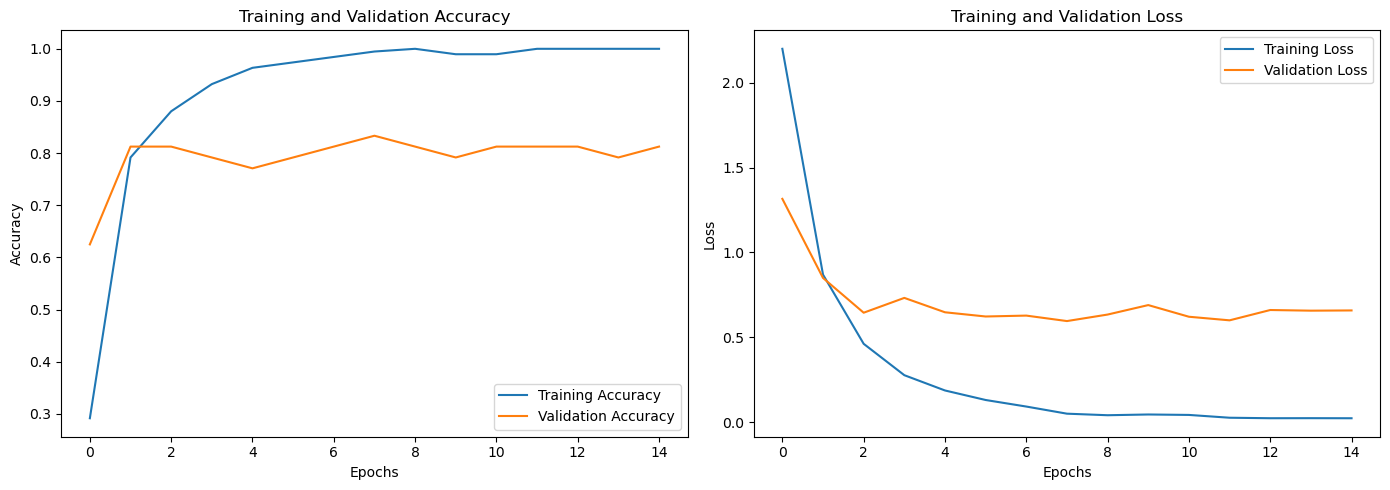

Training and validation graphs saved successfully!


In [27]:
import os
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

plt.figure(figsize=(14, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

plt.savefig(
    "results/training_validation_metrics.png",
    bbox_inches="tight",
    dpi=150
)

plt.show()

print("Training and validation graphs saved successfully!")

## 23. Final Project Summary

This project developed a landmark recognition system using Deep Learning and Transfer Learning.

- **Dataset:** GLDv2 Top 51 Categories subset
- **Selected Classes:** 10 landmark categories
- **Total Images:** 300
- **Image Size:** 224 × 224 pixels
- **Pretrained Model:** MobileNetV2
- **Optimizer:** Adam
- **Training Epochs:** 15
- **Batch Size:** 16
- **Test Accuracy:** Approximately 83.33%

The trained model was evaluated using test accuracy, precision, recall, F1-score, and a confusion matrix.

The project also demonstrates individual landmark predictions with confidence scores.

## 24. Project Limitations

- The project uses a small subset of the GLDv2 dataset containing 300 images across 10 landmark categories.
- The dataset is not verified to contain exclusively Google Street View images.
- The limited dataset size may affect the model's ability to generalize to unseen landmark images.
- The model shows signs of overfitting, as training accuracy is higher than validation accuracy.
- The model currently recognizes only the 10 selected landmark categories.
- Prediction confidence does not guarantee that a prediction is correct.